In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas import DataFrame

In [3]:
creditos=pd.read_csv('Model_creditoPersonal.xls')

In [4]:
creditos

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0


In [5]:
creditos.info(), creditos.describe(), creditos.shape

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


(None,
                 ID          Age   Experience       Income      ZIP Code  \
 count  5000.000000  5000.000000  5000.000000  5000.000000   5000.000000   
 mean   2500.500000    45.338400    20.104600    73.774200  93152.503000   
 std    1443.520003    11.463166    11.467954    46.033729   2121.852197   
 min       1.000000    23.000000    -3.000000     8.000000   9307.000000   
 25%    1250.750000    35.000000    10.000000    39.000000  91911.000000   
 50%    2500.500000    45.000000    20.000000    64.000000  93437.000000   
 75%    3750.250000    55.000000    30.000000    98.000000  94608.000000   
 max    5000.000000    67.000000    43.000000   224.000000  96651.000000   
 
             Family        CCAvg    Education     Mortgage  Personal Loan  \
 count  5000.000000  5000.000000  5000.000000  5000.000000    5000.000000   
 mean      2.396400     1.937938     1.881000    56.498800       0.096000   
 std       1.147663     1.747659     0.839869   101.713802       0.294621   

In [6]:
creditos.nunique()

ID                    5000
Age                     45
Experience              47
Income                 162
ZIP Code               467
Family                   4
CCAvg                  108
Education                3
Mortgage               347
Personal Loan            2
Securities Account       2
CD Account               2
Online                   2
CreditCard               2
dtype: int64

In [7]:
creditos['ZIP Code']

0       91107
1       90089
2       94720
3       94112
4       91330
        ...  
4995    92697
4996    92037
4997    93023
4998    90034
4999    92612
Name: ZIP Code, Length: 5000, dtype: int64

In [8]:
conteo_codigo_postal=pd.DataFrame(creditos['ZIP Code'].value_counts())
conteo_codigo_postal

,count
ZIP Code,
94720,169
94305,127
95616,116
90095,71
93106,57
...,...
90068,1
94970,1
90813,1


In [9]:
top_zip = pd.DataFrame(creditos['ZIP Code'].value_counts())

In [10]:
top_zip.reset_index(inplace=True)

/tmp/ipykernel_8616/3016729060.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  top_zip.reset_index(inplace=True)


Text(0, 0.5, 'Codigos postales')

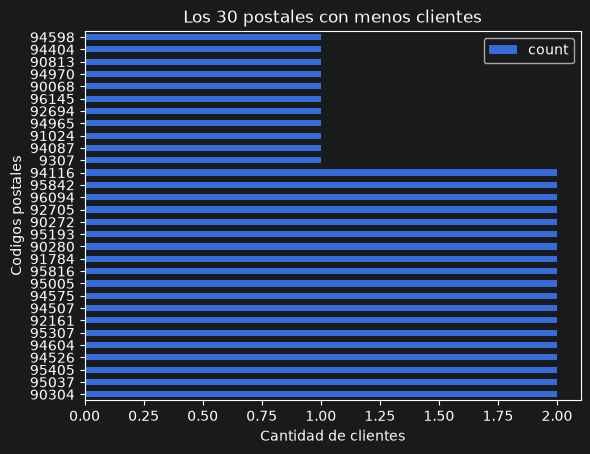

In [16]:
top_zip.tail(30).plot(kind='barh', y='count', x='ZIP Code')
plt.title('Los 30 postales con menos clientes')
plt.xlabel('Cantidad de clientes')
plt.ylabel('Codigos postales')

In [17]:
top_zip['count'].median(), top_zip['count'].mean()

(np.float64(6.0), np.float64(10.70663811563169))

In [18]:
top_zip['porcentaje_acumulado'] = (top_zip['count'].cumsum() / top_zip['count'].sum())*100

In [19]:
top_zip

,ZIP Code,count,porcentaje_acumulado
0,94720,169,3.38
1,94305,127,5.92
2,95616,116,8.24
3,90095,71,9.66
4,93106,57,10.80
...,...,...,...
462,90068,1,99.92
463,94970,1,99.94
464,90813,1,99.96
465,94404,1,99.98


In [20]:
codigos_otros=pd.DataFrame(top_zip[top_zip['porcentaje_acumulado']>70])

In [21]:
codigos_otros

,ZIP Code,count,porcentaje_acumulado
160,95120,9,70.08
161,90250,9,70.26
162,95023,9,70.44
163,92806,9,70.62
164,95605,9,70.80
...,...,...,...
462,90068,1,99.92
463,94970,1,99.94
464,90813,1,99.96
465,94404,1,99.98


In [45]:
df_codigos_postales_otros=codigos_otros['ZIP Code'].astype(int)


In [46]:
df_codigos_postales_otros

160    95120
161    90250
162    95023
163    92806
164    95605
       ...  
462    90068
463    94970
464    90813
465    94404
466    94598
Name: ZIP Code, Length: 307, dtype: int64

In [47]:
lista_boleana_otros = creditos['ZIP Code'].iloc[creditos['ZIP Code'].isin(df_codigos_postales_otros)]

In [48]:
lista_boleana_otros

14      91741
16      95010
20      94015
29      94104
38      94114
        ...  
4984    94043
4986    95825
4990    95023
4992    90037
4993    91801
Name: ZIP Code, Length: 1505, dtype: int64

In [53]:
codigos_postales_eliminar =creditos['ZIP Code'].isin(df_codigos_postales_otros)

In [54]:
codigos_postales_eliminar

0       False
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Name: ZIP Code, Length: 5000, dtype: bool

In [56]:
codigos_postales_eliminar.value_counts()

ZIP Code
False    3495
True     1505
Name: count, dtype: int64

In [198]:
lista_boleana_otros = pd.DataFrame(lista_boleana_otros)

In [68]:
creditos['ZIP Code'] = creditos['ZIP Code'].astype(str)

In [70]:
creditos.loc[codigos_postales_eliminar, 'ZIP Code'] = 'Otros'

<Axes: ylabel='ZIP Code'>

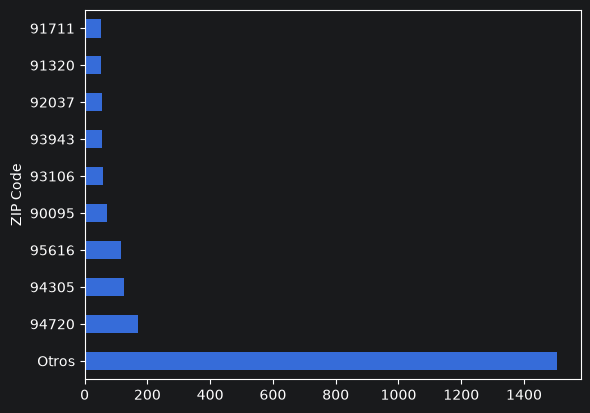

In [76]:
creditos['ZIP Code'].value_counts().head(10).plot(kind='barh', y='count', x='ZIP Code')

In [71]:
top_zip.reset_index(inplace=True)

/tmp/ipykernel_21298/3016729060.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  top_zip.reset_index(inplace=True)


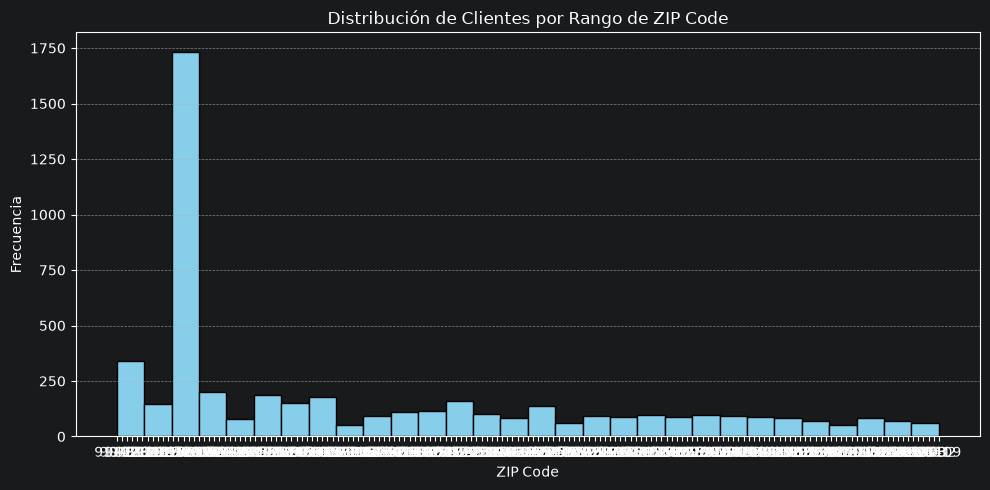

In [77]:
plt.figure(figsize=(10, 5))
plt.hist(creditos['ZIP Code'], bins=30, edgecolor='black', color='skyblue')
plt.title('Distribución de Clientes por Rango de ZIP Code')
plt.xlabel('ZIP Code')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [102]:
creditos['Age'].describe()

count    5000.000000
mean       45.338400
std        11.463166
min        23.000000
25%        35.000000
50%        45.000000
75%        55.000000
max        67.000000
Name: Age, dtype: float64

<Axes: xlabel='Age'>

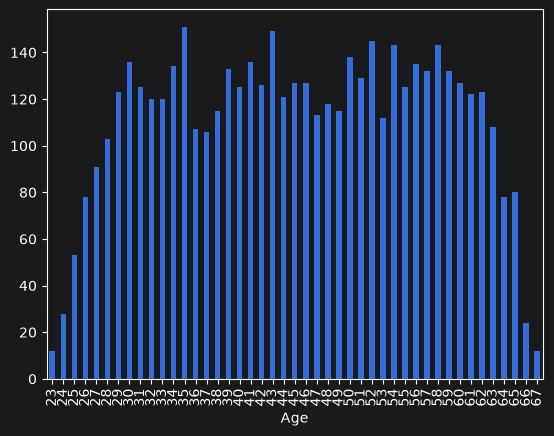

In [109]:
creditos.Age.value_counts().sort_index().plot(kind='bar')

In [113]:
creditos.Experience.describe()

count    5000.000000
mean       20.104600
std        11.467954
min        -3.000000
25%        10.000000
50%        20.000000
75%        30.000000
max        43.000000
Name: Experience, dtype: float64

In [114]:
creditos.Experience.isna().sum()

np.int64(0)

In [115]:
creditos.Experience.info()

<class 'pandas.Series'>
RangeIndex: 5000 entries, 0 to 4999
Series name: Experience
Non-Null Count  Dtype
--------------  -----
5000 non-null   int64
dtypes: int64(1)
memory usage: 39.2 KB


In [117]:
creditos['Experience'].iloc[creditos['Experience'] == -1]

89     -1
226    -1
524    -1
536    -1
540    -1
576    -1
583    -1
649    -1
670    -1
686    -1
909    -1
1173   -1
1428   -1
1522   -1
1905   -1
2102   -1
2430   -1
2545   -1
2848   -1
2980   -1
3076   -1
3157   -1
3279   -1
3284   -1
3292   -1
3394   -1
3425   -1
3824   -1
3946   -1
4015   -1
4088   -1
4582   -1
4957   -1
Name: Experience, dtype: int64

In [128]:
creditos.iloc[creditos['Experience'] >= 43]


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
2846,2847,67,43,105,Otros,4,1.7,2,0,0,0,0,1,0
3886,3887,67,43,79,95616,4,1.7,2,215,0,0,1,1,1
4360,4361,67,43,41,90024,2,1.1,1,0,0,0,0,0,0


In [145]:
creditos.loc[creditos['Experience']<0,'Experience']= 0

In [151]:
creditos['Experience'].value_counts(),creditos['Experience'].value_counts().sum()

(Experience
 32    154
 20    148
 9     147
 5     146
 23    144
 35    143
 25    142
 28    138
 18    137
 19    135
 26    134
 24    131
 3     129
 14    127
 16    127
 30    126
 27    125
 17    125
 34    125
 29    124
 22    124
 7     121
 15    119
 8     119
 6     119
 10    118
 0     118
 13    117
 33    117
 11    116
 37    116
 36    114
 21    113
 4     113
 31    104
 12    102
 38     88
 39     85
 2      85
 1      74
 40     57
 41     43
 42      8
 43      3
 Name: count, dtype: int64,
 np.int64(5000))

In [154]:
creditos.Income.isna().value_counts(), creditos.Income.describe()

(Income
 False    5000
 Name: count, dtype: int64,
 count    5000.000000
 mean       73.774200
 std        46.033729
 min         8.000000
 25%        39.000000
 50%        64.000000
 75%        98.000000
 max       224.000000
 Name: Income, dtype: float64)

In [161]:
creditos['Decada'] = pd.cut(x=creditos['Age'],bins=[20,30,40,50,60,70], labels=['20s','30s','40s','50s','60s',])

In [163]:
creditos.groupby('Decada').agg({'ID':'count', 'Income':'mean', 'CCAvg':'mean','Mortgage':'mean'}).round(2)

,ID,Income,CCAvg,Mortgage
Decada,,,,
20s,624,78.79,1.94,58.53
30s,1236,74.56,2.05,57.13
40s,1270,75.99,2.02,56.72
50s,1323,69.11,1.83,56.11
60s,547,72.41,1.77,53.17


<Axes: >

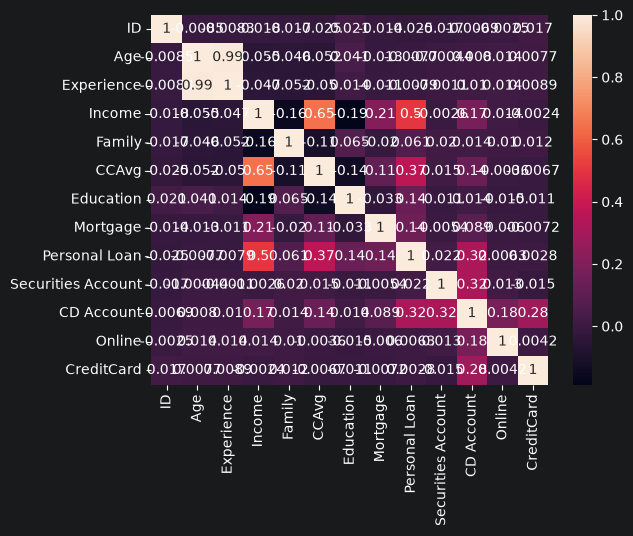

In [168]:
correlacion=creditos.corr(method='pearson', numeric_only=True)
sns.heatmap(correlacion, annot=True)

In [170]:
# Ver el porcentaje de uso de banca online según la década de edad
uso_digital = creditos.groupby('Decada', observed=False)[['Online', 'CreditCard']].mean() * 100
print(uso_digital.round(2))

        Online  CreditCard
Decada                    
20s      58.33       29.01
30s      60.52       28.64
40s      57.64       29.76
50s      61.38       29.55
60s      59.96       30.35


In [171]:
print(f"Asimetría (Skewness): {creditos['Age'].skew():.4f}")
print(f"Curtosis (Kurtosis): {creditos['Age'].kurt():.4f}")

Asimetría (Skewness): -0.0293
Curtosis (Kurtosis): -1.1531


In [182]:
creditos['Mortgage'].describe()

(count    5000.000000
 mean       56.498800
 std       101.713802
 min         0.000000
 25%         0.000000
 50%         0.000000
 75%       101.000000
 max       635.000000
 Name: Mortgage, dtype: float64,
 0        0
 1        0
 2        0
 3        0
 4        0
         ..
 4995     0
 4996    85
 4997     0
 4998     0
 4999     0
 Name: Mortgage, Length: 5000, dtype: int64)

In [2]:
creditos.to_csv('CreditoPersonal_procesados.csv')

NameError: name 'creditos' is not defined

In [1]:
mortgages =pd.cut(x= creditos['Mortgage'], bins=[0,100,200,300,400,500,600,700], labels=['100s','200s','300s','400s','400s','500s','600s','700s'],ordered=True)

NameError: name 'pd' is not defined

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns


In [8]:
df=pd.read_csv('CreditoPersonal_procesados.csv', index_col=0)
df.columns

Index(['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard', 'Decada'],
      dtype='str')

In [36]:
df.rename(columns={'Age':'Edad','Exp[eriencia':'Experiencia', 'Income':'Ingreso_Anual','ZIP Code':'Codigo postal','Family':'Familia','CCAvg':'Gasto_mensual_promedio','Education':'Nivel_educativo','Mortgage':'Valor_hipoteca','prestamo_personal':'Prestamo_personal','Securities Account':'Cuenta_valores','CD Account':'Certificado_deposito','banca_internet':'Banca_internet','CreditCard':'Tarjeta_credito'}, inplace=True)

/tmp/ipykernel_4559/1672491752.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Age':'Edad','Exp[eriencia':'Experiencia', 'Income':'Ingreso_Anual','ZIP Code':'Codigo postal','Family':'Familia','CCAvg':'Gasto_mensual_promedio','Education':'Nivel_educativo','Mortgage':'Valor_hipoteca','prestamo_personal':'Prestamo_personal','Securities Account':'Cuenta_valores','CD Account':'Certificado_deposito','banca_internet':'Banca_internet','CreditCard':'Tarjeta_credito'}, inplace=True)


In [37]:
df.columns

Index(['ID', 'Edad', 'Experiencia', 'Ingreso_Anual', 'Codigo postal',
       'Familia', 'Gasto_mensual_promedio', 'Nivel_educativo',
       'Valor_hipoteca', 'Prestamo_personal', 'Cuenta_valores',
       'Certificado_deposito', 'Banca_internet', 'Tarjeta_credito', 'Decada'],
      dtype='str')

In [44]:
df.groupby('Decada').agg({'Gasto_mensual_promedio':'sum','Ingreso_Anual':'sum' })

,Gasto_mensual_promedio,Ingreso_Anual
Decada,,
20s,1211.27,49165
30s,2532.63,92154
40s,2563.21,96510
50s,2416.30,91433
60s,966.28,39609


In [51]:
df['Gasto_mensual_promedio'].isna().sum()

np.int64(0)

In [61]:
df[df['Valor_hipoteca']>0].groupby('Decada')['Valor_hipoteca'].agg(
    clientes='count',
    mediana='median',
    media='mean',
    desv_est='std',
    maximo='max',
    pct_con_hipoteca=lambda x: (x > 0).mean() * 100
)

,clientes,mediana,media,desv_est,maximo,pct_con_hipoteca
Decada,,,,,,
20s,190,161.0,192.226316,100.149868,612,100.0
30s,394,147.0,179.230964,103.532222,635,100.0
40s,385,157.0,187.106494,102.723367,617,100.0
50s,405,150.0,183.296296,101.675961,601,100.0
60s,164,148.5,177.335366,93.391141,547,100.0


In [71]:
df.groupby('Nivel_educativo').agg({'Gasto_mensual_promedio':['sum', 'mean'],'Ingreso_Anual':['sum', 'mean'],})

Gasto_mensual_promedio           Ingreso_Anual           
                                   sum      mean           sum       mean
Nivel_educativo                                                          
1                              4738.70  2.260830        179389  85.586355
2                              2364.18  1.685089         90232  64.313614
3                              2586.81  1.723391         99250  66.122585

In [72]:
df.groupby('Nivel_educativo')[['Edad', 'Experiencia']].mean()

,Edad,Experiencia
Nivel_educativo,,
1,44.963740,20.075859
2,45.039914,19.786885
3,46.140573,20.491672


In [75]:
# Observa cómo cambia la tasa de aceptación del préstamo ('Personal Loan')
df.groupby('Nivel_educativo').agg(
    total_clientes=('Prestamo_personal', 'count'),
    tasa_prestamo=('Prestamo_personal', 'mean'),
    ingreso_mediana=('Ingreso_Anual', 'median')
)

,total_clientes,tasa_prestamo,ingreso_mediana
Nivel_educativo,,,
1,2096,0.044370,79.0
2,1403,0.129722,54.0
3,1501,0.136576,59.0


In [94]:
df.columns

Index(['ID', 'Edad', 'Experiencia', 'Ingreso_Anual', 'Codigo postal',
       'Familia', 'Gasto_mensual_promedio', 'Nivel_educativo',
       'Valor_hipoteca', 'Prestamo_personal', 'Cuenta_valores',
       'Certificado_deposito', 'Banca_internet', 'Tarjeta_credito', 'Decada'],
      dtype='str')

In [95]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      5000 non-null   int64  
 1   Edad                    5000 non-null   int64  
 2   Experiencia             5000 non-null   int64  
 3   Ingreso_Anual           5000 non-null   int64  
 4   Codigo postal           5000 non-null   str    
 5   Familia                 5000 non-null   int64  
 6   Gasto_mensual_promedio  5000 non-null   float64
 7   Nivel_educativo         5000 non-null   int64  
 8   Valor_hipoteca          5000 non-null   int64  
 9   Prestamo_personal       5000 non-null   int64  
 10  Cuenta_valores          5000 non-null   int64  
 11  Certificado_deposito    5000 non-null   int64  
 12  Banca_internet          5000 non-null   int64  
 13  Tarjeta_credito         5000 non-null   int64  
 14  Decada                  5000 non-null   str    
dty

In [98]:
df.describe()

,ID,Edad,Experiencia,Ingreso_Anual,Familia,Gasto_mensual_promedio,Nivel_educativo,Valor_hipoteca,Prestamo_personal,Cuenta_valores,Certificado_deposito,Banca_internet,Tarjeta_credito
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.119600,73.774200,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.440484,46.033729,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,0.000000,8.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [77]:
df['Prestamo_personal'].describe()

count    5000.000000
mean        0.096000
std         0.294621
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: Prestamo_personal, dtype: float64

In [80]:
df['Prestamo_personal'].value_counts(),df['Prestamo_personal'].isna().sum()

(Prestamo_personal
 0    4520
 1     480
 Name: count, dtype: int64,
 np.int64(0))

In [81]:
df['Cuenta_valores'].value_counts()

Cuenta_valores
0    4478
1     522
Name: count, dtype: int64

In [86]:
df['Certificado_deposito'].value_counts(), df['Certificado_deposito'].isna().sum()

(Certificado_deposito
 0    4698
 1     302
 Name: count, dtype: int64,
 np.int64(0))

In [89]:
df['Banca_internet'].value_counts(),df['Banca_internet'].isna().sum()

(Banca_internet
 1    2984
 0    2016
 Name: count, dtype: int64,
 np.int64(0))

In [91]:
df['Tarjeta_credito']

0       0
1       0
2       0
3       0
4       1
       ..
4995    0
4996    0
4997    0
4998    0
4999    1
Name: Tarjeta_credito, Length: 5000, dtype: int64

In [92]:
df['Tarjeta_credito'].value_counts(),df['Tarjeta_credito'].isna().sum()

(Tarjeta_credito
 0    3530
 1    1470
 Name: count, dtype: int64,
 np.int64(0))

In [99]:
display(df.groupby('Prestamo_personal')[['Ingreso_Anual', 'Gasto_mensual_promedio', 'Valor_hipoteca', 'Familia', 'Edad']].median())

,Ingreso_Anual,Gasto_mensual_promedio,Valor_hipoteca,Familia,Edad
Prestamo_personal,,,,,
0,59.0,1.4,0.0,2.0,45.0
1,142.5,3.8,0.0,3.0,45.0


In [100]:
display(pd.crosstab(df['Certificado_deposito'], df['Prestamo_personal'], normalize='index') * 100)

Prestamo_personal,0,1
Certificado_deposito,,
0,92.762878,7.237122
1,53.642384,46.357616


In [101]:
display(df.groupby(['Nivel_educativo', 'Prestamo_personal'])['Ingreso_Anual'].agg(['count', 'median', 'min']))

count  median  min
Nivel_educativo Prestamo_personal                    
1               0                   2003    75.0    8
                1                     93   139.0   60
2               0                   1221    48.0    8
                1                    182   142.0   69
3               0                   1296    51.0    8
                1                    205   149.0   64

In [110]:
data_entrenables =  df.drop(columns =['Prestamo_personal','Cuenta_valores','Certificado_deposito','Tarjeta_credito','ID'])
data_entrenables

,Edad,Experiencia,Ingreso_Anual,Codigo postal,Familia,Gasto_mensual_promedio,Nivel_educativo,Valor_hipoteca,Banca_internet,Decada
0,25,1,49,91107,4,1.6,1,0,0,20s
1,45,19,34,90089,3,1.5,1,0,0,40s
2,39,15,11,94720,1,1.0,1,0,0,30s
3,35,9,100,94112,1,2.7,2,0,0,30s
4,35,8,45,91330,4,1.0,2,0,0,30s
...,...,...,...,...,...,...,...,...,...,...
4995,29,3,40,92697,1,1.9,3,0,1,20s
4996,30,4,15,92037,4,0.4,1,85,1,20s
4997,63,39,24,93023,2,0.3,3,0,0,60s
4998,65,40,49,90034,3,0.5,2,0,1,60s


In [111]:
data_etiquetas= df[['Prestamo_personal','Cuenta_valores','Certificado_deposito','Tarjeta_credito']]
data_etiquetas

,Prestamo_personal,Cuenta_valores,Certificado_deposito,Tarjeta_credito
0,0,1,0,0
1,0,1,0,0
2,0,0,0,0
3,0,0,0,0
4,0,0,0,1
...,...,...,...,...
4995,0,0,0,0
4996,0,0,0,0
4997,0,0,0,0
4998,0,0,0,0


In [1]:
data_entrenables.to_csv('datos_entreno.csv')
data_etiquetas.to_csv('datos_etiquetas.csv')


NameError: name 'data_entrenables' is not defined

In [9]:
import pandas as pd
import seaborn as sns
import numpy as np

In [10]:
df_entrenable = pd.read_csv('datos_entreno.csv', index_col=0)
df_etiquetas = pd.read_csv('datos_etiquetas.csv', index_col=0)

In [58]:
df_etiquetas.columns

Index(['Prestamo_personal', 'Cuenta_valores', 'Certificado_deposito',
       'Tarjeta_credito'],
      dtype='str')

In [59]:
df_etiquetas_completas = df_etiquetas
df_etiquetas.drop(columns=[ 'Cuenta_valores', 'Certificado_deposito',
       'Tarjeta_credito'], inplace=True)

/tmp/ipykernel_9360/3479213872.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_etiquetas.drop(columns=[ 'Cuenta_valores', 'Certificado_deposito',


In [60]:
df_etiquetas

,Prestamo_personal
0,0
1,0
2,0
3,0
4,0
...,...
4995,0
4996,0
4997,0
4998,0


In [3]:
from sklearn.model_selection import train_test_split

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

In [14]:
df_entrenable.columns

NameError: name 'df_entrenable' is not defined

In [9]:
dataframe_completo=pd.merge(left=df_entrenable, right=df_etiquetas, on='Unnamed: 0', how='inner')

KeyError: 'Unnamed: 0'

In [11]:
dataframe_completo.drop(columns=['Unnamed: 0'], inplace=True)

NameError: name 'dataframe_completo' is not defined

In [10]:
dataframe_completo

NameError: name 'dataframe_completo' is not defined

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBClassifier


In [43]:
df_etiquetas.drop(columns =['Cuenta_valores', 'Certificado_deposito','Tarjeta_credito'], inplace=True)

/tmp/ipykernel_30263/1128333534.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_etiquetas.drop(columns =['Cuenta_valores', 'Certificado_deposito','Tarjeta_credito'], inplace=True)


In [44]:
xtrain, xtest, ytrain , ytest = train_test_split(df_entrenable,df_etiquetas,test_size=0.2, shuffle=True, random_state=42, stratify=df_etiquetas)

In [62]:
xtrain.shape, ytrain.shape, xtest.shape,ytest.shape

((4000, 10), (4000, 1), (1000, 10), (1000, 1))

In [45]:
xtrain, xval, ytrain , yval = train_test_split(xtrain,ytrain,test_size=0.2, shuffle=True, random_state=42, stratify=ytrain)

In [21]:
ytrain.drop(columns =['Cuenta_valores', 'Certificado_deposito','Tarjeta_credito'], inplace=True)
ytrain

/tmp/ipykernel_30263/4262319431.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ytrain.drop(columns =['Cuenta_valores', 'Certificado_deposito','Tarjeta_credito'], inplace=True)


KeyError: "['Cuenta_valores', 'Certificado_deposito', 'Tarjeta_credito'] not found in axis"

In [64]:
xval.shape, yval.shape

((800, 10), (800, 4))

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder, TargetEncoder

transformar_columnas = ColumnTransformer([
    ('robustscaler', RobustScaler(), ['Edad', 'Experiencia', 'Ingreso_Anual', 'Valor_hipoteca']),

    # Convierte 'Codigo postal' en 1 sola columna numérica con la tasa esperada del target
    ('target_enc', TargetEncoder(smooth='auto', cv=5), ['Codigo postal']),

    ('ordinal', OrdinalEncoder(
        categories=[['20s', '30s', '40s', '50s', '60s']],
        handle_unknown='use_encoded_value',
        unknown_value=-1,
        dtype=float
    ), ['Decada'])
], remainder='passthrough', sparse_threshold=0)  # <-- sparse_threshold=0 obliga a devolver NumPy denso

In [19]:
ytrain

,Prestamo_personal
1769,0
1032,0
1812,0
118,0
1770,0
...,...
238,0
17,0
2199,0
3559,0


In [164]:
xtrain

,Edad,Experiencia,Ingreso_Anual,Codigo postal,Familia,Gasto_mensual_promedio,Nivel_educativo,Valor_hipoteca,Banca_internet,Decada
2948,44,18,14,94720,2,0.1,3,98,0,40s
1802,29,3,121,Otros,2,1.3,1,0,0,20s
1561,46,20,73,93106,1,1.5,2,128,1,40s
3402,64,40,95,90095,2,0.0,3,0,1,60s
2448,51,26,42,92103,2,0.6,3,0,1,50s
...,...,...,...,...,...,...,...,...,...,...
2551,46,22,43,92120,2,2.1,3,0,1,40s
4227,32,7,111,90277,1,3.8,1,0,0,30s
3976,60,33,42,90277,4,2.5,2,194,1,50s
1779,34,9,68,94720,1,2.8,1,0,1,30s


In [46]:
xtrain_proc=transformar_columnas.fit_transform(xtrain, ytrain)
xval_proc=transformar_columnas.transform(xval)
xtest_proc=transformar_columnas.transform(xtest)


/home/abimael/Escritorio/Credito_bancario/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [25]:
xtrain_proc

array([[ 0.73684211,  0.84210526, -0.01666667, ...,  2.2       ,
         1.        ,  0.        ],
       [-0.47368421, -0.42105263, -0.35      , ...,  0.7       ,
         2.        ,  1.        ],
       [-0.15789474, -0.05263158,  1.08333333, ...,  4.7       ,
         1.        ,  1.        ],
       ...,
       [ 0.15789474,  0.21052632, -0.2       , ...,  1.3       ,
         2.        ,  0.        ],
       [ 0.26315789,  0.26315789,  0.08333333, ...,  1.5       ,
         2.        ,  0.        ],
       [-0.89473684, -0.89473684, -0.4       , ...,  0.2       ,
         1.        ,  1.        ]], shape=(3200, 10))

In [54]:
xtrain,xval

(array([[0.7368421052631579, 0.8421052631578947, -0.016666666666666666,
         ..., 1, 0, '50s'],
        [-0.47368421052631576, -0.42105263157894735, -0.35, ..., 2, 1,
         '30s'],
        [-0.15789473684210525, -0.05263157894736842, 1.0833333333333333,
         ..., 1, 1, '40s'],
        ...,
        [0.15789473684210525, 0.21052631578947367, -0.2, ..., 2, 0, '40s'],
        [0.2631578947368421, 0.2631578947368421, 0.08333333333333333, ...,
         2, 0, '50s'],
        [-0.8947368421052632, -0.8947368421052632, -0.4, ..., 1, 1, '20s']],
       shape=(3200, 170), dtype=object),
 array([[-0.4, -0.35, 0.9454545454545454, ..., 2, 1, '30s'],
        [-0.85, -0.85, 0.9454545454545454, ..., 2, 0, '20s'],
        [-0.3, -0.35, -0.23636363636363636, ..., 3, 0, '30s'],
        ...,
        [0.15, 0.15, 2.327272727272727, ..., 1, 0, '40s'],
        [0.05, 0.0, 0.9272727272727272, ..., 1, 1, '40s'],
        [-0.7, -0.7, -0.18181818181818182, ..., 1, 1, '30s']],
       shape=(800, 157), d

In [30]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit

# --- PASO 0: Sanitizar target a enteros [0, 1, 2, 3] ---
def sanitizar_target(y):                                   # Define la función para estandarizar las etiquetas a un array 1D de enteros
    if sp.issparse(y):                                     # Verifica si el target es una matriz dispersa de SciPy (ej. generada por encoders)
        y = y.toarray()                                    # Convierte la matriz dispersa a un arreglo denso tradicional en memoria
    if isinstance(y, (pd.DataFrame, pd.Series)):           # Comprueba si el objeto proviene de Pandas (DataFrame o Series)
        y = y.to_numpy()                                   # Extrae el array subyacente de NumPy descartando índices y nombres de columna
    y = np.asarray(y)                                      # Garantiza que cualquier otra estructura (listas, tuplas) sea un ndarray de NumPy

    if y.ndim == 2:                                        # Evalúa si el arreglo tiene 2 dimensiones (filas y columnas)
        if y.shape[1] == 1:                                # Si es un vector columna de forma (N, 1)
            y = y.ravel()                                  # Aplana la columna a un vector unidimensional plano de forma (N,)
        else:                                              # Si tiene 2 o más columnas (ej. formato One-Hot Encoding de 4 clases)
            y = np.argmax(y, axis=1)                       # Extrae el índice con el valor máximo por fila para convertir One-Hot a etiquetas enteras (0, 1, 2, 3)
    elif y.ndim > 2:                                       # Contempla casos atípicos donde el array tenga 3 o más dimensiones
        y = y.ravel()                                      # Aplana completamente el tensor a una sola dimensión continua

    return y.astype(int)                                   # Fuerza el tipo de dato a enteros nativos y retorna el vector limpio

def combinar_matrices(X_train, X_val):
    if isinstance(X_train, pd.DataFrame) and isinstance(X_val, pd.DataFrame):
        return pd.concat([X_train, X_val], axis=0, ignore_index=True)
    elif sp.issparse(X_train) or sp.issparse(X_val):
        return sp.vstack([X_train, X_val])
    else:
        return np.vstack([np.asarray(X_train), np.asarray(X_val)])

# 1. Targets y matrices
ytrain_1d = sanitizar_target(ytrain)
yval_1d = sanitizar_target(yval)

X_full = combinar_matrices(xtrain_proc, xval_proc)
y_full = np.concatenate([ytrain_1d, yval_1d])

if isinstance(X_full, np.ndarray) and not sp.issparse(xval_proc):
    xval_eval = np.asarray(xval_proc)
else:
    xval_eval = xval_proc

num_clases = len(np.unique(y_full))
print(f"Dataset listo: {X_full.shape[0]} muestras, {num_clases} clases detectadas.")

# --- PASO 2: PredefinedSplit (-1 train, 0 val) ---
split_indices = np.concatenate([
    np.full(len(ytrain_1d), -1),
    np.full(len(yval_1d), 0)
])
ps = PredefinedSplit(test_fold=split_indices)

# --- PASO 3: XGBoost Multiclase ---
modelo_base = XGBClassifier(
    n_estimators=500,
    objective='multi:softprob',     # Devuelve probabilidades por clase (requerido para ROC-AUC OvR)
    num_class=num_clases,           # 4 clases
    eval_metric='mlogloss',         # Métrica multiclase para early stopping
    early_stopping_rounds=20,
    random_state=42,
    tree_method='hist'
)

param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 0.1, 0.2]
}

grid_search = GridSearchCV(
    estimator=modelo_base,
    param_grid=param_grid,
    cv=ps,
    scoring='roc_auc_ovr',          # ROC-AUC multiclase One-vs-Rest
    n_jobs=-1,
    verbose=1,
    refit=False,
    error_score='raise'
)

# --- PASO 4: Fit con early stopping ---
grid_search.fit(
    X_full,
    y_full,
    eval_set=[(xval_eval, yval_1d)],
    verbose=False
)
mejor_modelo=grid_search.best_params_
print(f"\nMejores hiperparámetros: {grid_search.best_params_}")
print(f"Mejor ROC-AUC OvR en Validación: {grid_search.best_score_:.4f}")

Dataset listo: 4000 muestras, 4 clases detectadas.
Fitting 1 folds for each of 324 candidates, totalling 324 fits


ValueError: `y_score` needs to be of shape `(n_samples, n_classes)`, since `y_true` contains multiple classes. Got `y_score.shape=(800,)`.

In [71]:
mi_modelo=XGBClassifier(
    n_estimators=500,
    objective='multi:softprob',     # Devuelve probabilidades por clase (requerido para ROC-AUC OvR)
    num_class=num_clases,           # 4 clases
    eval_metric='mlogloss',         # Métrica multiclase para early stopping
    early_stopping_rounds=20,
    random_state=42,
    tree_method='hist',
    colsample_bylevel=mejor_modelo['colsample_bytree'],
    gamma=mejor_modelo['gamma'],
    learning_rate=mejor_modelo['learning_rate'],
    max_depth=mejor_modelo['max_depth'],
    min_child_weight=mejor_modelo['min_child_weight'],
    subsample=mejor_modelo['subsample']
)
mi_modelo.fit(
    xtrain_proc,
    ytrain_1d,
    eval_set=[(xval_eval, yval_1d)],
    verbose=False
)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,0.8
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",20
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg

In [49]:
mi_modelo

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,1.0
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",20
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg

In [26]:
ytest.shape

(1000, 4)

In [72]:
# 1. Asegurar que X de test esté preprocesado igual que train y val
# (Si ya tienes xtest_proc listo en memoria, omite esta línea)
# xtest_proc = preprocesador.transform(xtest)

# 2. Generar predicciones de clase pasando X (no y)
yprediccion_test = mejor_modelo.predict(xtest_proc)

# 3. Si necesitas probabilidades para curvas ROC o métricas tipo AUC:
yproba_test = mejor_modelo.predict_proba(xtest_proc)

AttributeError: 'dict' object has no attribute 'predict'

In [29]:
from sklearn.metrics import roc_auc_score, f1_score

In [ ]:
yprediccion_test

In [30]:
# 1. Obtener probabilidades continuas
y_prob_test = modelo_xg.predict_proba(xtest_proc)

# Si tu modelo predice las 4 columnas a la vez (multietiqueta):
score = roc_auc_score(ytest, y_prob_test, average='macro')
print(f"ROC-AUC Real (Probabilidades): {score:.4f}")

# Si estás prediciendo solo 'Prestamo_personal':
# score = roc_auc_score(ytest, y_prob_test[:, 1])

NameError: name 'modelo_xg' is not defined

In [93]:
np.array(ytest)[:,0]

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,

In [97]:
yproba_test[:,1]

array([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       1., 1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0.,
       0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0.,
       1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [98]:
import numpy as np
from sklearn.metrics import roc_auc_score

# 1. Obtener probabilidades continuas (no etiquetas duras 0/1)
yproba_test = mi_modelo.predict(xtest_proc)
yproba_test
a=roc_auc_score(ytest, yproba_test[:,1])
a

0.9706397492625369

In [15]:
import torch.nn as nn
import torch

In [151]:
type(int(xtrain_proc.shape[1]))

int

In [38]:
xtrain_tensor.shape[1]

10

In [27]:
class Modelo_predictivo(nn.Module):
    def __init__(self, caracteristicas):
        super().__init__()
        self.secuencia = nn.Sequential(
            # Entrada -> Normalización de entrada (protege contra columnas en escalas distintas)
            nn.BatchNorm1d(caracteristicas),

            # Capa Oculta 1
            nn.Linear(caracteristicas, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa Oculta 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa de Salida (1 logit binario)
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.secuencia(x)
torch.manual_seed(42)
mi_modelo1=Modelo_predictivo(int(xtrain_tensor.shape[1]))


NameError: name 'xtrain_tensor' is not defined

In [107]:
mi_modelo

Modelo_predictivo(
  (secuencia): Sequential(
    (0): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (1): Linear(in_features=10, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [48]:
y_train_arreglo=np.array(ytrain)
y_train_arreglo.shape

y_val_arreglo=np.array(yval)
y_val_arreglo
y_test_arreglo = np.array(ytest)
y_test_arreglo.shape, y_train_arreglo.shape

((1000, 1), (3200, 1))

In [42]:
xval_proc.shape,y_train_arreglo.shape

((800, 10), (3200, 1))

In [49]:

def a_denso(X):
    return X.toarray() if sp.issparse(X) else np.asarray(X)

# 1. Tensores X
xtrain_tensor = torch.tensor(a_denso(xtrain_proc), dtype=torch.float32)
xval_tensor   = torch.tensor(a_denso(xval_proc),   dtype=torch.float32)
xtest_tensor  = torch.tensor(a_denso(xtest_proc),  dtype=torch.float32)

# 2. Tensores y -> usando .reshape(-1, 1)
ytrain_tensor = torch.tensor(y_train_arreglo, dtype=torch.float32).reshape(-1, 1)
yval_tensor   = torch.tensor(y_val_arreglo,   dtype=torch.float32).reshape(-1, 1)
ytest_tensor  = torch.tensor(y_test_arreglo,  dtype=torch.float32).reshape(-1, 1)

print(f"y shapes corregidos -> Train: {ytrain_tensor.shape} | Val: {yval_tensor.shape} | Test: {ytest_tensor.shape}")

y shapes corregidos -> Train: torch.Size([3200, 1]) | Val: torch.Size([800, 1]) | Test: torch.Size([1000, 1])


In [50]:
from torch.utils.data import DataLoader, TensorDataset
Tensordataset_xtrain=TensorDataset(xtrain_tensor,ytrain_tensor)
dataloader_xtrain=DataLoader(Tensordataset_xtrain, shuffle=True,batch_size=128)

In [60]:
xval_tensor.shape, yval_tensor.shape

(torch.Size([800, 10]), torch.Size([3200, 1]))

In [51]:
from torch.utils.data import TensorDataset
tensordataset_xval = TensorDataset(xval_tensor,yval_tensor)
dataloader_xval=DataLoader(tensordataset_xval, batch_size=128, shuffle=False)

In [136]:
ytrain_tensor

tensor([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]])

In [117]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
class Modelo_predictivo(nn.Module):
    def __init__(self, caracteristicas):
        super().__init__()
        self.secuencia = nn.Sequential(
            # Entrada -> Normalización de entrada (protege contra columnas en escalas distintas)
            nn.BatchNorm1d(caracteristicas),

            # Capa Oculta 1
            nn.Linear(caracteristicas, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa Oculta 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa de Salida (1 logit binario)
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.secuencia(x)
torch.manual_seed(42)
mi_modelo1=Modelo_predictivo(int(xtrain_tensor.shape[1]))

peso_1 = (ytrain_tensor == 1).sum()
peso_2 =(ytrain_tensor == 0).sum()
pesos=torch.tensor([peso_2/peso_1], dtype=torch.float32)
criterio=nn.BCEWithLogitsLoss(pos_weight=pesos)
optimizador_adamw = AdamW(mi_modelo1.parameters(), lr=0.0003, weight_decay=0.01)
Lr= ReduceLROnPlateau(optimizador_adamw, mode='min', patience=2, factor=0.1 )

In [138]:
ytrain_tensor

tensor([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]])

In [139]:
ytrain_tensor

tensor([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]])

Época 01 | Perdida entrenamiento: 0.6097, perdida validacion: 1.3313
Época 02 | Perdida entrenamiento: 0.4264, perdida validacion: 0.3829
Época 03 | Perdida entrenamiento: 0.3631, perdida validacion: 0.2961
Época 04 | Perdida entrenamiento: 0.3185, perdida validacion: 0.2723
Época 05 | Perdida entrenamiento: 0.3636, perdida validacion: 0.4887
Época 06 | Perdida entrenamiento: 0.3126, perdida validacion: 0.2776
Época 07 | Perdida entrenamiento: 0.2696, perdida validacion: 0.1988
Época 08 | Perdida entrenamiento: 0.2583, perdida validacion: 0.2624
Época 09 | Perdida entrenamiento: 0.3000, perdida validacion: 0.2429
Época 10 | Perdida entrenamiento: 0.2757, perdida validacion: 0.2987
Época 11 | Perdida entrenamiento: 0.2407, perdida validacion: 0.2926
Época 12 | Perdida entrenamiento: 0.2716, perdida validacion: 0.2255
Early stopping activado en época 12. Mejor Val Loss: 0.1988 (Época 7)


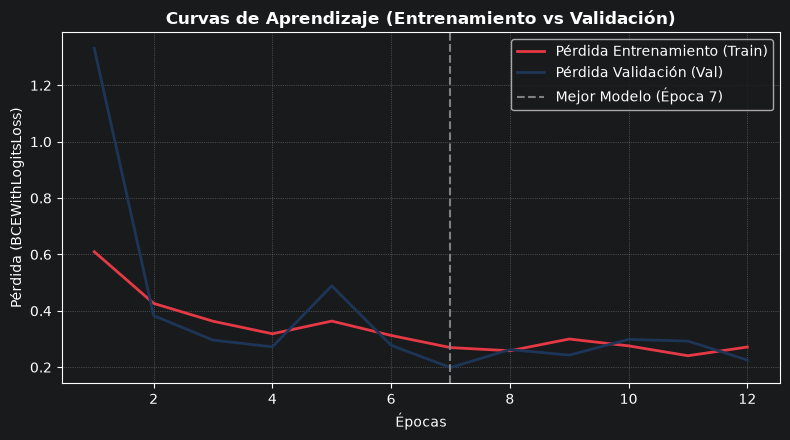

In [59]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt  # <-- 1. Importar matplotlib

class Modelo_predictivo(nn.Module):
    def __init__(self, caracteristicas):
        super().__init__()
        self.secuencia = nn.Sequential(

            # Capa Oculta 1
            nn.Linear(caracteristicas, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa Oculta 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa de Salida (1 logit binario)
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.secuencia(x)

torch.manual_seed(42)
mi_modelo1 = Modelo_predictivo(int(xtrain_tensor.shape[1]))

peso_1 = (ytrain_tensor == 1).sum()
peso_2 = (ytrain_tensor == 0).sum()
pesos = torch.tensor([peso_2 / peso_1], dtype=torch.float32)
criterio = nn.BCEWithLogitsLoss(pos_weight=pesos)
optimizador_adamw = AdamW(mi_modelo1.parameters(), lr=0.05, weight_decay=0.01)
Lr = ReduceLROnPlateau(optimizador_adamw, mode='min', patience=3, factor=0.5)


epocas = 100
ruta_guardar_modelo = 'mi_modelo_produccion.pth'
mejor_perdida = float('inf')
mejor_epoca = 1          # <-- 2. Guardar cuál fue la mejor época
conteo_paciencia = 0
paciencia_maxima = 5

# <-- 2. Listas para guardar la evolución de las pérdidas
historial_train = []
historial_val = []

for epoca in range(epocas):
    mi_modelo1.train()
    perdida_acumulada_acumulada = 0.0
    for xtrain, ytrainloader in (dataloader_xtrain):
        optimizador_adamw.zero_grad()
        prediccion = mi_modelo1(xtrain)
        perdida = criterio(prediccion, ytrainloader)
        perdida.backward()
        optimizador_adamw.step()
        perdida_acumulada_acumulada += perdida.item() * xtrain.size(0)

    perdida_acumulada_promedio = perdida_acumulada_acumulada / len(dataloader_xtrain.dataset)
    historial_train.append(perdida_acumulada_promedio)  # <-- 3. Guardar pérdida de train

    mi_modelo1.eval()
    perdida_val_acumulada = 0.0
    with torch.no_grad():
        for x, y in (dataloader_xval):
            prediccion = mi_modelo1(x)
            perdida = criterio(prediccion, y)
            perdida_val_acumulada += perdida.item() * x.size(0)

        perdida_val_promedio = perdida_val_acumulada / len(dataloader_xval.dataset)

    historial_val.append(perdida_val_promedio)          # <-- 3. Guardar pérdida de validación

    print(f'Época {epoca+1:02d} | Perdida entrenamiento: {perdida_acumulada_promedio:.4f}, perdida validacion: {perdida_val_promedio:.4f}')

    if perdida_val_promedio < mejor_perdida:
        mejor_perdida = perdida_val_promedio
        mejor_epoca = epoca + 1                         # <-- Actualizar mejor época
        conteo_paciencia = 0
        torch.save(mi_modelo1.state_dict(), ruta_guardar_modelo)
    else:
        conteo_paciencia += 1
        if conteo_paciencia >= paciencia_maxima:
            print(f"Early stopping activado en época {epoca+1}. Mejor Val Loss: {mejor_perdida:.4f} (Época {mejor_epoca})")
            break

    Lr.step(perdida_val_promedio)

mi_modelo1.load_state_dict(torch.load(ruta_guardar_modelo))
torch.save(mi_modelo1.state_dict(), ruta_guardar_modelo)
# <-- 4. Graficar las curvas de aprendizaje
epocas_ejecutadas = range(1, len(historial_train) + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(epocas_ejecutadas, historial_train, label='Pérdida Entrenamiento (Train)', color='#e63946', linewidth=2)
plt.plot(epocas_ejecutadas, historial_val, label='Pérdida Validación (Val)', color='#1d3557', linewidth=2)
plt.axvline(x=mejor_epoca, color='gray', linestyle='--', label=f'Mejor Modelo (Época {mejor_epoca})')

plt.title('Curvas de Aprendizaje (Entrenamiento vs Validación)', fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (BCEWithLogitsLoss)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

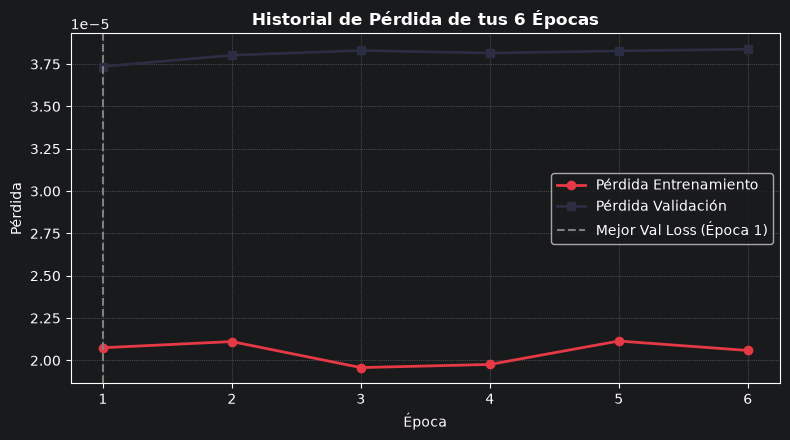

In [83]:
import matplotlib.pyplot as plt

epocas_corrida = [1, 2, 3, 4, 5, 6]
train_loss = [2.074666e-05, 2.111051e-05, 1.957443e-05, 1.975938e-05, 2.114287e-05, 2.058520e-05]
val_loss   = [3.735575e-05, 3.802156e-05, 3.830344e-05, 3.815153e-05, 3.827811e-05, 3.837593e-05]

plt.figure(figsize=(8, 4.5))
plt.plot(epocas_corrida, train_loss, label='Pérdida Entrenamiento', color='#e63946', marker='o', linewidth=2)
plt.plot(epocas_corrida, val_loss, label='Pérdida Validación', color='#2b2d42', marker='s', linewidth=2)
plt.axvline(x=1, color='gray', linestyle='--', label='Mejor Val Loss (Época 1)')

plt.title('Historial de Pérdida de tus 6 Épocas', fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.xticks(epocas_corrida)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [61]:
# Ejecutar una vez en el notebook de entrenamiento para guardar el set de prueba limpio:
torch.save({
    'xtest': xtest_tensor,
    'ytest': ytest_tensor,
    'columnas': list(df_entrenable.columns)  # Ajusta 'X' al nombre de tu DataFrame de características
}, 'datos_test_produccion.pt')

In [55]:
import torch
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

# 1. Poner el modelo en modo evaluación (desactiva Dropout y fija BatchNorm)
mi_modelo1.eval()

# 2. Apagar el cálculo de gradientes para inferencia
with torch.no_grad():
    logits_test = mi_modelo1(xtest_tensor)
    # Convertir logits a probabilidades entre 0 y 1
    probabilidades_test = torch.sigmoid(logits_test)

# 3. Pasar de tensores de PyTorch a arreglos 1D de NumPy
y_true = ytest_tensor.cpu().numpy().ravel()
y_prob = probabilidades_test.cpu().numpy().ravel()

# 4. Calcular métricas
roc_auc = roc_auc_score(y_true, y_prob)
pr_auc = average_precision_score(y_true, y_prob)  # PR-AUC (ideal para datos desbalanceados)

print(f"ROC-AUC en Test: {roc_auc:.4f}")
print(f"PR-AUC en Test:  {pr_auc:.4f}")

# Opcional: Reporte clasificando con umbral de 0.5
y_pred_clase = (y_prob >= 0.5).astype(int)
print("\nReporte de Clasificación:")
print(classification_report(y_true, y_pred_clase))

ROC-AUC en Test: 0.9940
PR-AUC en Test:  0.9706

Reporte de Clasificación:
              precision    recall  f1-score   support

         0.0       1.00      0.95      0.97       904
         1.0       0.67      0.97      0.79        96

    accuracy                           0.95      1000
   macro avg       0.83      0.96      0.88      1000
weighted avg       0.97      0.95      0.95      1000



In [56]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report
y_true = ytest_tensor.cpu().numpy().ravel()
y_prob = probabilidades_test.cpu().numpy().ravel()

# Suponiendo que 'y_test' son las etiquetas reales y 'probabilidades' son las salidas con torch.sigmoid()
precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)

# Calcular el F1-Score para cada umbral posible
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
indice_mejor = np.argmax(f1_scores)
mejor_umbral = thresholds[indice_mejor]

print(f"Mejor umbral encontrado: {mejor_umbral:.4f} (F1-Score máximo: {f1_scores[indice_mejor]:.4f})\n")

# Nuevo reporte aplicando el umbral óptimo en lugar de 0.5
predicciones_optimizadas = (y_prob >= mejor_umbral).astype(int)
print(classification_report(y_true, predicciones_optimizadas))

Mejor umbral encontrado: 0.8851 (F1-Score máximo: 0.9362)

              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99       904
         1.0       0.96      0.92      0.94        96

    accuracy                           0.99      1000
   macro avg       0.97      0.96      0.96      1000
weighted avg       0.99      0.99      0.99      1000



In [57]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix

# 1. Calcular precisión y recall para todos los umbrales posibles
precisiones, recalls, umbrales = precision_recall_curve(y_true, y_prob)

# 2. Calcular F1-Score en cada punto (evitando división por cero)
f1_scores = (2 * precisiones[:-1] * recalls[:-1]) / (precisiones[:-1] + recalls[:-1] + 1e-8)

# 3. Extraer el umbral que maximiza el F1-Score
idx_optimo = np.argmax(f1_scores)
umbral_optimo = umbrales[idx_optimo]

print(f"Umbral óptimo encontrado: {umbral_optimo:.4f} (F1 máximo: {f1_scores[idx_optimo]:.4f})")

# 4. Nuevo reporte aplicando el umbral optimizado
y_pred_optimizado = (y_prob >= umbral_optimo).astype(int)
print("\nReporte con Umbral Optimizado:")
print(classification_report(y_true, y_pred_optimizado))
print("Matriz de Confusión [TN, FP / FN, TP]:")
print(confusion_matrix(y_true, y_pred_optimizado))

Umbral óptimo encontrado: 0.8851 (F1 máximo: 0.9362)

Reporte con Umbral Optimizado:
              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99       904
         1.0       0.96      0.92      0.94        96

    accuracy                           0.99      1000
   macro avg       0.97      0.96      0.96      1000
weighted avg       0.99      0.99      0.99      1000

Matriz de Confusión [TN, FP / FN, TP]:
[[900   4]
 [  8  88]]


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_curve

# ==================== 0. DEFINICIÓN Y CARGA DEL MODELO ====================
class Modelo_predictivo(nn.Module):
    def __init__(self, caracteristicas):
        super().__init__()
        self.secuencia = nn.Sequential(
            # Capa Oculta 1
            nn.Linear(caracteristicas, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa Oculta 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Capa de Salida (1 logit binario)
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.secuencia(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Detecta automáticamente si el archivo tiene extensión .pth o no
ruta_modelo = 'mi_modelo_produccion.pth' if os.path.exists('mi_modelo_produccion.pth') else 'mi_modelo_produccion'

# Instanciar la arquitectura y cargar los pesos entrenados
mi_modelo_produccion = Modelo_predictivo(int(xtest_tensor.shape[1])).to(device)
mi_modelo_produccion.load_state_dict(torch.load(ruta_modelo, map_location=device, weights_only=True))
mi_modelo_produccion.eval()

# Generar predicciones base y umbral óptimo F1 directamente desde el modelo cargado
with torch.no_grad():
    logits_test = mi_modelo_produccion(xtest_tensor.to(device))
    probabilidades_test = torch.sigmoid(logits_test)

y_true = ytest_tensor.cpu().numpy().ravel()
y_prob = probabilidades_test.cpu().numpy().ravel()

precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
indice_mejor = np.argmax(f1_scores)
mejor_umbral = thresholds[indice_mejor]
f1_base = f1_scores[indice_mejor]

# ==================== 1. SIMULACIÓN FINANCIERA (VALOR ESPERADO) ====================
ganancia_prestamo = 450.0  # USD de margen neto por cada Préstamo Personal colocado con éxito (VP)
costo_contacto    = 15.0   # USD de costo operativo de telemarketing/campaña por cliente contactado (VP + FP)
costo_oportunidad = 100.0  # USD de penalización/pérdida por dejar ir a un cliente que sí quería el préstamo (FN)

def calcular_beneficio_neto(y_real, y_prob, umbral):
    pred = (y_prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()

    ingresos = tp * ganancia_prestamo
    costos_campana = (tp + fp) * costo_contacto
    perdida_clientes = fn * costo_oportunidad

    beneficio_neto = ingresos - costos_campana - perdida_clientes
    return beneficio_neto, tp, fp, fn

umbrales_eval = np.linspace(0.05, 0.99, 200)
beneficios = [calcular_beneficio_neto(y_true, y_prob, u)[0] for u in umbrales_eval]

idx_max_dinero = np.argmax(beneficios)
umbral_financiero = umbrales_eval[idx_max_dinero]

ben_050, tp_050, fp_050, fn_050 = calcular_beneficio_neto(y_true, y_prob, 0.50)
ben_f1,  tp_f1,  fp_f1,  fn_f1  = calcular_beneficio_neto(y_true, y_prob, mejor_umbral)
ben_fin, tp_fin, fp_fin, fn_fin = calcular_beneficio_neto(y_true, y_prob, umbral_financiero)

print("=== COMPARATIVA DE IMPACTO DE NEGOCIO (EN 1,000 CLIENTES) ===")
print(f"1. Umbral Estándar (0.5000)   -> Beneficio Neto: ${ben_050:,.2f} USD | Falsas alarmas (FP): {fp_050}")
print(f"2. Umbral Óptimo F1 ({mejor_umbral:.4f}) -> Beneficio Neto: ${ben_f1:,.2f} USD | Falsas alarmas (FP): {fp_f1}")
print(f"3. Umbral Máx. ROI ({umbral_financiero:.4f})  -> Beneficio Neto: ${ben_fin:,.2f} USD | Falsas alarmas (FP): {fp_fin}\n")

# ==================== 2. EXPLICABILIDAD DE LA RED NEURONAL ====================
x_test_np = xtest_tensor.cpu().numpy().copy()

# Si tienes los nombres reales de tus columnas (ej. list(X.columns)), reemplaza esta lista:
nombres_columnas = [f"Columna_{i}" for i in range(x_test_np.shape[1])]

importancias = []

with torch.no_grad():
    for col in range(x_test_np.shape[1]):
        x_permutado = x_test_np.copy()
        np.random.seed(42)
        np.random.shuffle(x_permutado[:, col])

        tensor_perm = torch.tensor(x_permutado, dtype=torch.float32).to(device)
        prob_perm = torch.sigmoid(mi_modelo_produccion(tensor_perm)).cpu().numpy().ravel()
        pred_perm = (prob_perm >= mejor_umbral).astype(int)

        tp_p = np.sum((pred_perm == 1) & (y_true == 1))
        fp_p = np.sum((pred_perm == 1) & (y_true == 0))
        fn_p = np.sum((pred_perm == 0) & (y_true == 1))
        f1_perm = (2 * tp_p) / (2 * tp_p + fp_p + fn_p + 1e-8)

        caida_f1 = max(0, f1_base - f1_perm)
        importancias.append(caida_f1)

# Graficar ambas conclusiones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(umbrales_eval, beneficios, color='#2a9d8f', linewidth=2.2, label='Beneficio Neto ($ USD)')
ax1.axvline(0.50, color='#e63946', linestyle=':', label=f'Umbral 0.50 (${ben_050:,.0f})')
ax1.axvline(mejor_umbral, color='#1d3557', linestyle='--', label=f'Umbral F1 {mejor_umbral:.2f} (${ben_f1:,.0f})')
ax1.axvline(umbral_financiero, color='#f4a261', linestyle='-.', label=f'Umbral ROI {umbral_financiero:.2f} (${ben_fin:,.0f})')
ax1.set_title('Optimización de Retorno Financiero por Umbral', fontweight='bold')
ax1.set_xlabel('Umbral de Probabilidad')
ax1.set_ylabel('Beneficio Neto Estimado (USD)')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

df_imp = pd.DataFrame({'Variable': nombres_columnas, 'Importancia': importancias}).sort_values('Importancia', ascending=True).tail(8)
ax2.barh(df_imp['Variable'], df_imp['Importancia'], color='#457b9d')
ax2.set_title('Explicabilidad: Variables Clave en la Red (Caída en F1)', fontweight='bold')
ax2.set_xlabel('Impacto en F1-Score al permutar la variable')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [62]:
import torch

mi_modelo1.eval()

# Extraer los nombres reales de las columnas en el orden exacto en que salen del ColumnTransformer
nombres_reales = [col.split('__')[-1] for col in transformar_columnas.get_feature_names_out()]

paquete_produccion = {
    # 1. Pesos del mejor modelo movidos a CPU
    'model_state_dict': {k: v.cpu() for k, v in mi_modelo1.state_dict().items()},

    # 2. Metadatos de arquitectura
    'arquitectura': {
        'caracteristicas': int(xtrain_tensor.shape[1]),
        'capas_ocultas': [128, 64],
        'dropout': 0.2
    },

    # 3. Preprocesador completo (RobustScaler + TargetEncoder + OrdinalEncoder) y umbral óptimo
    'preprocesador': transformar_columnas,
    'umbral_optimo': float(mejor_umbral),
    'nombres_columnas': nombres_reales,

    # 4. Conjunto de prueba limpio para reproducir métricas, ROI y explicabilidad
    'test_data': {
        'xtest': xtest_tensor.cpu(),
        'ytest': ytest_tensor.cpu()
    }
}

ruta_bundle = 'propensity_net_produccion.pt'
torch.save(paquete_produccion, ruta_bundle)

print(f"Paquete guardado exitosamente en '{ruta_bundle}'")
print(f"Umbral óptimo: {paquete_produccion['umbral_optimo']:.4f}")
print(f"Columnas ({len(nombres_reales)}): {nombres_reales}")

Paquete guardado exitosamente en 'propensity_net_produccion.pt'
Umbral óptimo: 0.8851
Columnas (10): ['Edad', 'Experiencia', 'Ingreso_Anual', 'Valor_hipoteca', 'Codigo postal', 'Decada', 'Familia', 'Gasto_mensual_promedio', 'Nivel_educativo', 'Banca_internet']
